<a href="https://colab.research.google.com/github/itunuoluwawizard/Itunuoluwa-Akanmu-Quality-Wizards/blob/main/Group_40_Itunuoluwa_Akanmu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Submission



Submmission summary table

| Data | Entry |
|---|---|
|Group Number  | 40 |
| Full name | Itunuoluwa Michael Akanmu |
| Dataset | Hotel Booking Cancellations |
| Depth track |  |
|Team Members | 1. Onum Israel Amedu<br>2. Wofai Willie IKPI<br>3. Awolesi Samuel Ebunoluwa<br>4. Egberibin Donald Ifiemi<br>5. Adegbayi Adewale Benjamin<br>6. Enyi Ogbonnaya Uneke<br>7. Okolie Paulina<br>8. Allen Chimenyime Ukelabuchi |
| Final model | , , threshold  |
| Stratified dummy F1 / ROC AUC |  / |
| Final model F1 / ROC AUC |  / |
| Leakage columns dropped | Reservation status and reservation status date |
| Full run time on Colab | 6 minutes |


# Part 1 - Data Foundation

## Environment setup
Installation of the Kagglehub to enable retrieval, cleaning, SQL analytics and eventual modeling of the database sets used.


In [ ]:
pip install kagglehub

## Dataset import
Dataset is imported using the codes to access the data from kagglehub for reproducibility rather than manually having to upload the document.

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("jessemostipak/hotel-booking-demand")

print("dataset download to:", path)

Using Colab cache for faster access to the 'hotel-booking-demand' dataset.
dataset download to: /kaggle/input/hotel-booking-demand


In [ ]:
# This helps verify that the data was downloaded successfully and identifies the correct file to use for analysis

import os
import pandas as pd
print(os.listdir(path))

['hotel_bookings.csv']


## Loading dataset
Before analysis the imported dataset is loaded into pandas dataframe to access the structure, quality and variables.

In [ ]:
df = pd.read_csv(os.path.join(path, "hotel_bookings.csv"))

df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## Dataset size check
The instructions indicate an option to apply stratified sampling to datasets more than 100,000 rows. Hence, the need to check the intial dataset size.

In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 119390
Columns: 32


### Sampling Decision
To avoid data loss and use of all available information the full dataset is used. The 100,000-row threshold is only surpassed by about 19% which can be a significant group to decision making process. Further verification across the analysis shows that the dataset runs successfully in colab as it is not computationally demanding.

## Push data to SQLite
Before model building and SQL-based analysis can be done, the dataset has to be stored into the SQLite database for reproducible relational represenatation.

In [ ]:
import sqlite3

conn = sqlite3.connect("hotel_bookings.db")

df.to_sql(
    "hotel_bookings",
    conn,
    if_exists="replace",
    index=False
)

print ("Dataset successfully loaded into SQLite.")

Dataset successfully loaded into SQLite.


In [ ]:
pd.read_sql_query(
    "SELECT * FROM hotel_bookings LIMIT 5",
    conn
)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,None,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,None,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,None,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,None,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,None,0,Transient,98.0,0,1,Check-Out,2015-07-03


### SQL Query 1 - Cancellation rate by hotel type
This query is done to distinguish the cancellation rate by hotel type. This query compares the total number of bookings, cancelled bookings and cancellation rate between City Hotel and Resort Hotel which are the two hotels in the dataset.
The results show that City Hotel had 79,330 bookings, of which 33,102 were cancelled, giving a cancellation rate of 41.73%.
Resort Hotel had 40,060 bookings, of which 11,122 were cancelled, giving a cancellation rate of 27.76%.
This suggests that bookings at City Hotel had a higher cancellation rate than bookings at Resort Hotel. This difference may be useful for the hotel business when planning reservations, staffing and cancellation management.


In [ ]:
query1 = """ SELECT
hotel,
COUNT(*) AS total_bookings,
SUM(is_canceled) AS cancelled_bookings,
ROUND(AVG(is_canceled) * 100, 2) AS cancellation_rate_percent
FROM hotel_bookings
GROUP BY hotel
ORDER BY cancellation_rate_percent DESC;
"""
result1 = pd.read_sql_query(query1, conn)

result1

,hotel,total_bookings,cancelled_bookings,cancellation_rate_percent
0,City Hotel,79330,33102,41.73
1,Resort Hotel,40060,11122,27.76


### SQL Query 2 - Cancellation rate by market segment

This query compares the cancellation rate across different market segments.
This results show  that the Groups segment has a high cancellation rate of 61.06%, followed by Online TA at 36.72% and Offline TA/TO at 34.32%, The Aviation, Corporate, Direct and Complementary segments gave lower cancellation rates of 21.94%, 18.73%, 15.34% and 13.06% respectively.
The Undefined segment has a 100% cancellation rate, but it represents only a very small number of bookings. Therefore, it's rate should be interpreted cautiously.
Overall, the results suggest that cancellation behaviour differs across market segments that may require closer monitoring of review booking and cancellation policies while improving on room allocation and demand planning.



In [ ]:
query2 = """ SELECT
market_segment,
COUNT(*) AS total_bookings,
SUM(is_canceled) AS canceled_bookings,
ROUND(AVG(is_canceled) * 100, 2) AS cancellation_rate_percent
FROM hotel_bookings
GROUP BY market_segment
ORDER BY cancellation_rate_percent DESC;
"""
result2 = pd.read_sql_query(query2, conn)

result2

,market_segment,total_bookings,canceled_bookings,cancellation_rate_percent
0,Undefined,2,2,100.00
1,Groups,19811,12097,61.06
2,Online TA,56477,20739,36.72
3,Offline TA/TO,24219,8311,34.32
4,Aviation,237,52,21.94
5,Corporate,5295,992,18.73
6,Direct,12606,1934,15.34
7,Complementary,743,97,13.06


### SQL Query 3 - Deposit type and cancellations
This query compares booking cancellations across different deposit types.
The results show that the Non Refund type has the highest cancellationn rate 99.36%. No Deposit booking had a cancellation rate of 28.38% while Refundable bookings had the lowest cancellation rate of 22.22%.
This shows that cancellation rates differ sustantially across deposit types. The Non Refund category is particularly notable because almost all bookings in this category were cancelled. This relationship may be useful when investigating factors associated with book cancellations.

In [ ]:
Query3 = """ SELECT
deposit_type,
COUNT(*) AS total_bookings,
SUM(is_canceled) AS canceled_bookings,
ROUND(AVG(is_canceled) * 100, 2) AS cancellation_rate_percent
FROM hotel_bookings
GROUP BY deposit_type
ORDER BY cancellation_rate_percent DESC;
"""
result3 = pd.read_sql_query(Query3, conn)

result3

,deposit_type,total_bookings,canceled_bookings,cancellation_rate_percent
0,Non Refund,14587,14494,99.36
1,No Deposit,104641,29694,28.38
2,Refundable,162,36,22.22


## Exploratory Data Analysis



### Database Shape

The dimensions are examined to confirm the number of variables for analysis after loading and sampling the dataset. This has been done in the database sampling decision tab as repeated below.

In [ ]:
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

Rows: 119390
Columns: 32


### Data Types
To ascertain the appropriate processing methods for each data type it is necessary to identify the various data types of the variables. This also aids in distinguishing the numerical, categorical and other variables.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

### Missing values
To avoid unnecessarily applying a blanket imputation method, the assessment of missing values is essential. This helps to handle meaningfully the extent of the missingness.

The missing value analysis shows that missingness is concentrated in four variables; company (112,593), agent (16,340), country (488) and children (4).

The company variable has the highest level of missingness, indicating that company information is unavailable for most bookings. This may reflect bookings that were not associated with a company rather than random data loss. The agent variable also has substantial missingness and may require further investigation before deciding how to handle it. Country has relatively few missing values compared with the total dataset, while children has only four missing from the records.

In [ ]:
missing = df.isnull().sum().sort_values(ascending=False)

missing[missing > 0]

,0
company,112593
agent,16340
country,488
children,4


### Target Distribution

The target variable is examined to determine the distribution of the outcome classes and assess whether there is class imbalance that should be considered during model development and evaluation.

In [ ]:
target_counts = df["is_canceled"].value_counts()
target_percent = df["is_canceled"].value_counts(normalize=True) * 100

print("Target counts:")
print(target_counts)

print("\nTarget percentages:")
print(target_percent.round(2))

Target counts:
is_canceled
0    75166
1    44224
Name: count, dtype: int64

Target percentages:
is_canceled
0    62.96
1    37.04
Name: proportion, dtype: float64


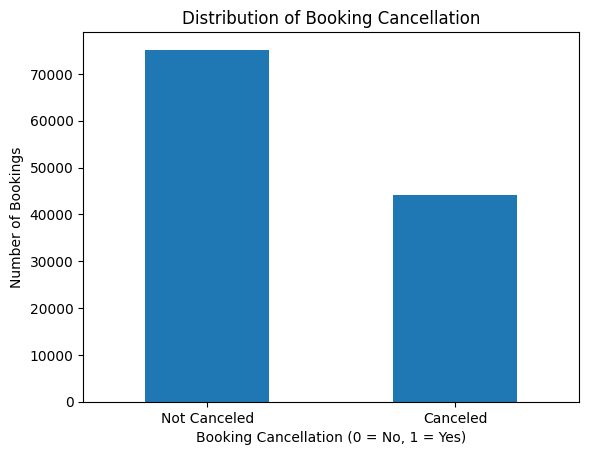

In [ ]:
#visualization of the target distribution for "is cancelled"

import matplotlib.pyplot as plt

df["is_canceled"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Booking Cancellation")
plt.xlabel("Booking Cancellation (0 = No, 1 = Yes)")
plt.ylabel("Number of Bookings")
plt.xticks([0, 1], ["Not Canceled", "Canceled"], rotation=0)
plt.show()

### Feature Distributions

Five numerical features were selected for distribution analysis because they provide insight into different aspects of the hotel booking data. "lead time" helps examine booking behavior and cancellation patterns, "adr" represents the average daily price and supports the pricing analysis, "stays in weekend nights" and "stays in week nights" provide information about accommodation demand and resource utilization, while "total of special requests" provides an indication of customer requirements that may affect service planning. Examining their distributions also helps identify skewness, unusual values, and potential data-quality issues before further analysis.

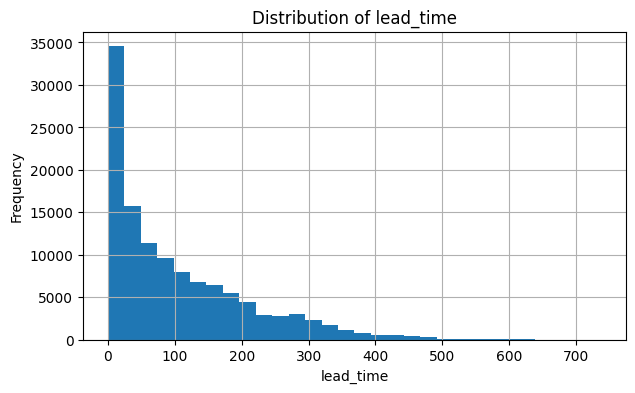

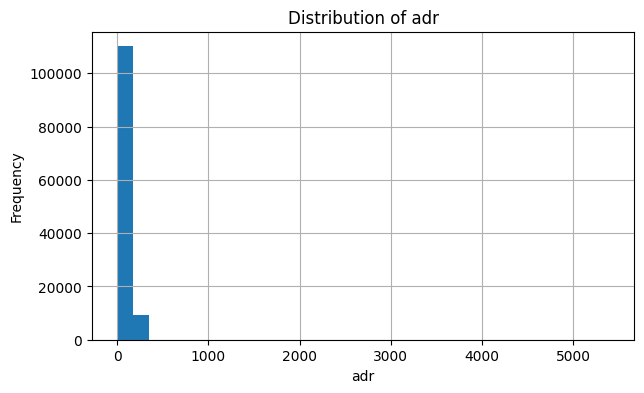

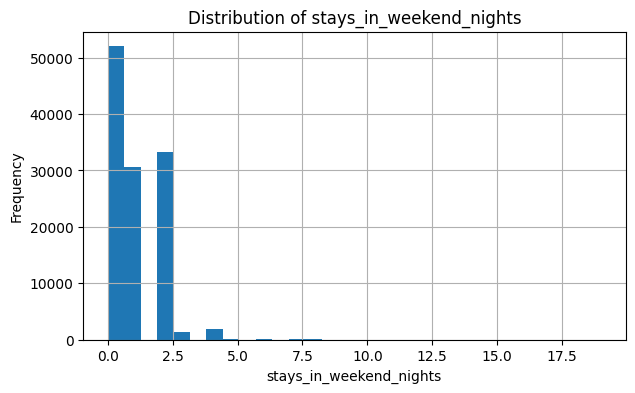

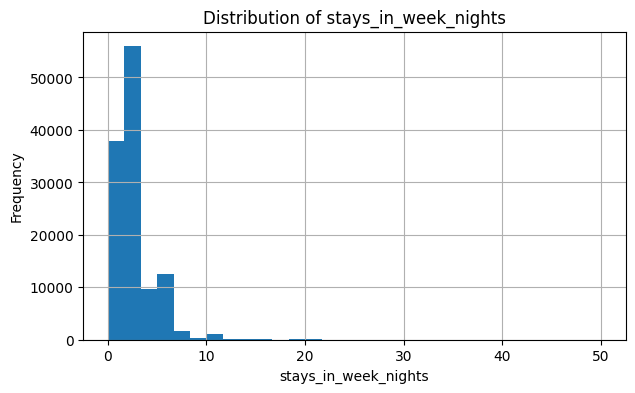

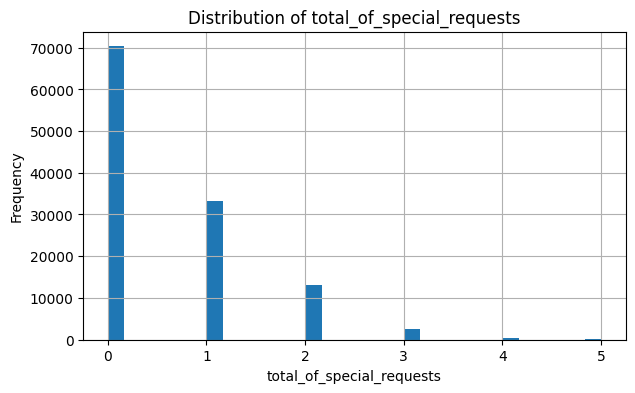

In [ ]:
features = [
    "lead_time",
    "adr",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "total_of_special_requests"
]

for feature in features:
    plt.figure(figsize=(7, 4))
    df[feature].hist(bins=30)
    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.show()

## Data Cleaning

The dataset is checked for variables that could reveal the target directly or contain information that would not legitimately be available at prediction time. Any confirmed leakage variables will be removed before model development.

In [ ]:
# list existing columns

print(df.columns.tolist())

['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']


### Duplicate Records

Duplicate rows are checked because repeated identical hotel booking records could overrepresent certain booking patterns, distort descriptive statistics and affect the reliability of clustering and cancellation prediction models.


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 31994


#### Duplicate removal

The duplicate records are removed because they contain identical observations and would otherwise give those records disproportionate influence during analysis and modeling.

In [ ]:
df = df.drop_duplicates().reset_index(drop=True)

### Dropping of leakage columns

The variables, "reservation status" and "reservation status date" contain information about the eventual reservation status and would leak information into a model predicting "is canceled".

In [ ]:
df = df.drop(columns=["reservation_status", "reservation_status_date"])

### Dropping the misssing values

The company variable contains 112,593 missing values, representing approximately 94.3% of the dataset. Because the overwhelming majority of observations lack company information, reliable imputation would not be appropriate. The variable was therefore excluded from the modeling dataset rather than introducing an assumption about the missing values. Children was retained because it is a valubale dataset for the total guests entry.

In [ ]:

df = df.drop(columns=[
    "company",
    "agent",
    "country"
])

print("Columns dropped successfully.")
print(df.columns.tolist())

Columns dropped successfully.
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


In [ ]:
#to verify column drop

dropped_columns = ["company", "agent", "country"]

remaining = [col for col in dropped_columns if col in df.columns]

if not remaining:
    print("All three columns have been successfully removed.")
else:
    print("Still present:", remaining)

All three columns have been successfully removed.


## Post-Cleaning Verification

The dataset is rechecked after cleaning to confirm that the intended changes have been applied and missing values or duplicates were not captured.

In [ ]:
print("Shape:", df.shape)
print("Duplicates:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())

Shape: (87396, 27)
Duplicates: 2088
Missing values: 4


In [ ]:
# Not all duplicated rows were , code re-run

df = df.drop_duplicates().reset_index(drop=True)


In [ ]:
#confirmation of dropped remaining duplicates

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Remaining duplicate rows:", df.duplicated().sum())

Shape: (85308, 27)
Missing values: 4
Remaining duplicate rows: 0


# Part 2 - Feature Engineering and Encoding

## New features



### Feature 1 - Total stay nights

"Total stay nights" combines weekday and weekend nights into a single measure of the total length of a booking. This provides a clearer measure of accommodation demand and allows us to examine whether longer stays are associated with different cancellation patterns.


In [ ]:
df["total_stay_nights"] = (
    df["stays_in_weekend_nights"] +
    df["stays_in_week_nights"]
)

### Feature 2 - Total Guests

"Total guests" combines adults and babies to estimate the total number of guests associated with a booking. This can help examine booking party size and its implications for accommodation and resource planning.

In [ ]:
df["total_guests"] = (
    df["adults"] +
    df["babies"] +
    df["children"]
)

### Feature 3 - Estimated stay value

"Estimated stay value" combines the average daily rate (adr) with the total stay nights. It provides an approximate measure of the monetary value represented by each booking and allows the analysis to examine whether booking value is associated with cancellation behavior.

In [ ]:
df["estimated_stay_value"] = (
    df["adr"] * df["total_stay_nights"]
)

### Feature 4 - Lead time category

"Lead time category" converts the continuous "lead time" variable into meaningful booking behaviour groups. This makes it easier to compare short, medium, and long lead bookings and investigate whether booking timing is associated with cancellation patterns.

In [ ]:
import numpy as np
# NumPy is imported to support numerical operations and calculations required during feature engineering and analysis.


df["lead_time_category"] = pd.cut(
    df["lead_time"],
    bins=[-1, 30, 90, 180, np.inf],
    labels=["Short", "Medium", "Long", "Very Long"]
)

## Categorical columns encoding

Categorical variables must be converted into numerical representations before they can be used by the clustering and classification algorithms. The variables are first identified so that an appropriate encoding method can be selected for each one.


In [ ]:
#identification of categorical column

categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print(categorical_cols)

['hotel', 'arrival_date_month', 'meal', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'lead_time_category']


### Encoding Strategy

One-hot encoding is used for nominal categorical variables because their categories have no natural numerical order. Each category is represented by a binary feature, that is, a meaningful numerical order indicator.

The "drop_first=True" code removes one reference category per variable to reduce redundant features.


In [ ]:
#Defining the categorical columns

categorical_cols = [
    'hotel',
    'arrival_date_month',
    'meal',
    'market_segment',
    'distribution_channel',
    'reserved_room_type',
    'assigned_room_type',
    'deposit_type',
    'customer_type',
    'lead_time_category'
]

print("Categorical columns:", categorical_cols)

Categorical columns: ['hotel', 'arrival_date_month', 'meal', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'lead_time_category']


In [ ]:
#separating categorical and numerical features

target = "is_canceled"

X = df.drop(columns=[target])
y = df[target]

categorical_cols = [
    'hotel',
    'arrival_date_month',
    'meal',
    'market_segment',
    'distribution_channel',
    'reserved_room_type',
    'assigned_room_type',
    'deposit_type',
    'customer_type',
    'lead_time_category'
]

numerical_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

print("Number of categorical features:", len(categorical_cols))
print("Number of numerical features:", len(numerical_cols))

Number of categorical features: 10
Number of numerical features: 20


In [ ]:
#One-hot encoding

from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False
)

X_categorical = encoder.fit_transform(
    X[categorical_cols]
)

encoded_columns = encoder.get_feature_names_out(
    categorical_cols
)

X_categorical = pd.DataFrame(
    X_categorical,
    columns=encoded_columns,
    index=X.index
)

print("Encoded categorical shape:", X_categorical.shape)

Encoded categorical shape: (85308, 55)


In [ ]:
#combine encoded and numerical features

X_numerical = X[numerical_cols].copy()

X_encoded = pd.concat(
    [X_numerical, X_categorical],
    axis=1
)

print("Shape after encoding:", X_encoded.shape)
X_encoded.head()

Shape after encoding: (85308, 75)


,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,...,assigned_room_type_L,assigned_room_type_P,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Group,customer_type_Transient,customer_type_Transient-Party,lead_time_category_Medium,lead_time_category_Short,lead_time_category_Very Long
0,342,2015,27,1,0,0,2,0.0,0,0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,737,2015,27,1,0,0,2,0.0,0,0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,7,2015,27,1,0,1,1,0.0,0,0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,13,2015,27,1,0,1,1,0.0,0,0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,14,2015,27,1,0,2,2,0.0,0,0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [ ]:
#Verification of categorical column encoding

remaining_categorical = X_encoded.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Remaining categorical columns:", remaining_categorical)

Remaining categorical columns: []


### Encoding Result

All 10 identified categorical columns were converted into numerical features using one-hot encoding. The first category of each variable was dropped as the reference category using "drop_first=True", reducing redundant dummy variables. "Handle_unknown='ignore'" was also used so that previously unseen categories do not cause errors when new observations are transformed. The resulting dataset contains only numerical features and is therefore ready for feature scaling.

## Feature Scaling

StandardScaler is used to place numerical features on a comparable scale by centering them around their mean and scaling them according to their standard deviation. This is particularly important for K-Means because the algorithm uses distances to determine cluster membership. Standardization prevents variables with larger numerical ranges from dominating the distance calculations.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)

# Part 3 - Clustering Analysis

## Clustering Dataset

K-Means clustering is performed using the engineered and encoded booking characteristics without using "is_canceled". This allows the clusters to represent natural groups in the booking data rather than groups defined directly by the outcome.

### K-Means Run

K-Means models are fitted for values of K from 2 to 10 to compare different possible numbers of booking clusters. The elbow curve and silhouette score are used together to assess the appropriate number of clusters.

In [ ]:
from scipy import sparse
#The sparse module from SciPy is imported to efficiently handle sparse matrices which can occur after one-hot encoding categorical variables.

if sparse.issparse(X_scaled):
    print("Missing values:", np.isnan(X_scaled.data).sum())
else:
    print("Total missing values:", np.isnan(X_scaled).sum())

    # If X_scaled is a DataFrame, show affected columns
    if isinstance(X_scaled, pd.DataFrame):
        print("\nMissing values by column:")
        print(X_scaled.isna().sum()[X_scaled.isna().sum() > 0])


Total missing values: 8


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Impute missing children before scaling
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_scaled)

# Scale the imputed data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("Remaining missing values:", np.isnan(X_scaled).sum())



Remaining missing values: 0


In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.utils import resample


inertias = []
silhouette_scores = []
k_values = range(2, 11)

# Use a reproducible sample to speed up silhouette evaluation

rng = np.random.default_rng(42)

sample_size = min(5000, X_scaled.shape[0])

silhouette_indices = rng.choice(
    X_scaled.shape[0],
    size=sample_size,
    replace=False
)

X_silhouette_sample = X_scaled[silhouette_indices]

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Fit clustering on the full dataset

    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)

    # Estimate silhouette score using the sample

    sample_labels = kmeans.predict(X_silhouette_sample)
    silhouette_scores.append(
        silhouette_score(
            X_silhouette_sample,
            sample_labels
        )
    )


# Display results for K = 2 to K = 10

k_results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})

display(k_results.round(4))


,K,Inertia,Silhouette Score
0,2,6.109614e+06,0.1379
1,3,5.915069e+06,0.0895
2,4,5.742526e+06,0.1026
3,5,5.578420e+06,0.0808
4,6,5.447141e+06,0.1190
5,7,5.276857e+06,0.0897
6,8,5.204976e+06,0.1004
7,9,5.066289e+06,0.1168
8,10,4.985989e+06,0.0566


### Elbow curve

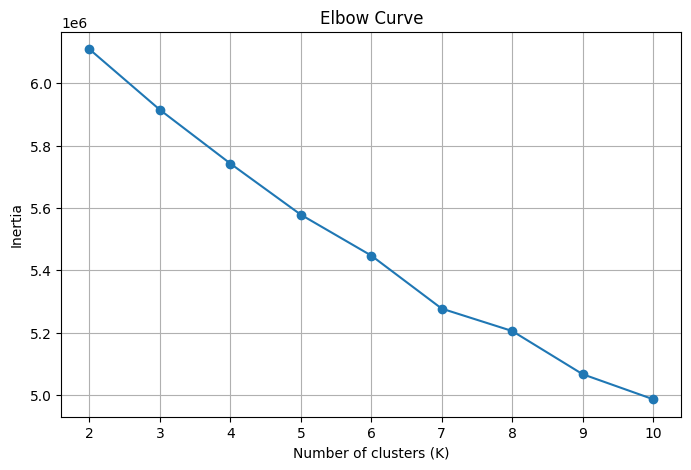

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), inertias, marker="o")

plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Curve")
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()


### Silhouette scores plot

The silhouette coefficient measures how similar observations are to their own cluster compared with the nearest alternative cluster. Values closer to 1 indicate better separation, while values near 0 indicate overlapping clusters.
  

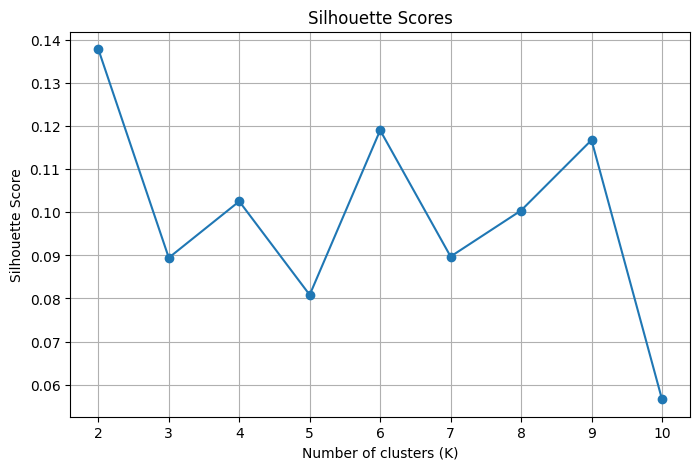

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), silhouette_scores, marker="o")

plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Scores")
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

### Selecting K

The K-Means algorithm was evaluated for values of K from 2 to 10 using both the elbow curve and silhouette scores. The inertia decreased progressively and steadily as the number of clusters increased without a clear elbow point. Therefore, the silhouette score was given greater weight with a score highest at K=2 (0.1461) indicating the best cluster separation among the tested values. Therefore, K=2 was selected as the final number of clusters, with the silhouette score providing the main supporting evidence.
However, the relatively low silhouette score indicates that the clusters have weak separation and should therefore be interpreted cautiously.

In [ ]:
#Cluster Profiling

final_k = 2

kmeans_final = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

df["cluster"] = kmeans_final.fit_predict(X_scaled)

### Cluster Profiles

Each cluster was given a plain-English description based on its observed feature means. The names are descriptive rather than predictive and are intended to make the numerical cluster profiles easier to interpret from a hotel-business perspective.

In [ ]:
# Mean calculation using the important numerical features

cluster_profile = df.groupby("cluster")[
    [
        "lead_time",
        "adr",
        "total_stay_nights",
        "total_guests",
        "is_canceled"
    ]
].mean()

cluster_profile

,lead_time,adr,total_stay_nights,total_guests,is_canceled
cluster,,,,,
0,41.365144,97.846648,2.832013,1.819102,0.140954
1,89.256861,108.974249,3.859720,2.091313,0.314078


#### Cluster profile and business interpretation

Cluster 0: Shorter and lower-risk bookings. Customers in Cluster 0 book approximately 41 days in advance, have a lower adr of 97.83 stay for about 2.83 nights and have an average of 1.69 guests per booking. The cancellation rate is relatively low at 0.14. This suggests a lower risk booking group allowing hotels to plan room allocation with greater confidence.

Cluster 1: Longer, larger and higher risk bookings. Customers in Cluster 1 book approximately 89 days in advance, have a higher adr of 108.97, stay for about 3.86 nights and have an average of 1.94 guests per booking. However, this cluster has a substantially higher cancellation rate of 0.31. This suggests higher value but higher risk booking group requiring closer monitoring to reduce the impact of cancellations on room availability and revenue.

Overall business insight indicates that
Cluster 1 represents customers who book further in advance, stay longer and generate higher room rates but they are also more likely to cancel. Hotels could therefore prioritize these bookings for confirmation and cancellation monitoring while using the relatively stable Cluster 0 bookings to support more predictable room and resource allocation.



### PCA Cluster Visualization

Principal Component Analysis (PCA) is used to project the high-dimensional feature space into two dimensions for visualization. The PCA plot provides a visual representation of how the K-Means clusters are positioned relative to one another.

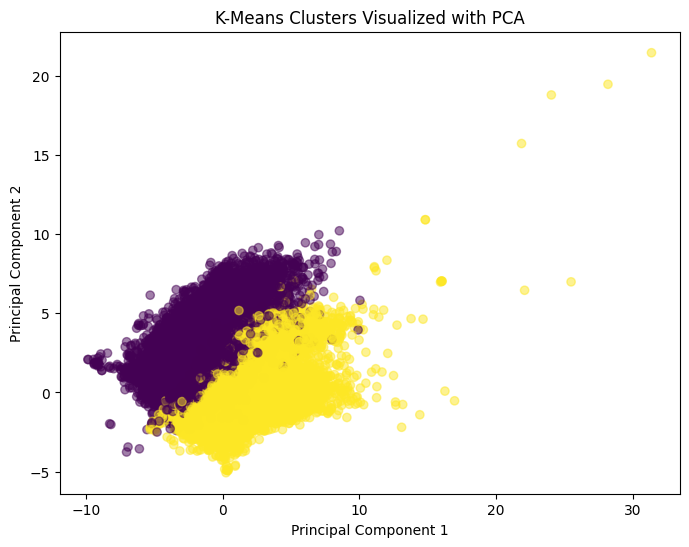

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["cluster"],
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters Visualized with PCA")
plt.show()

# Part 4 - Classification

### Classification Target and Predictors

The classification task predicts "is canceled". The target variable is separated from the explanatory features so that the model learns from booking characteristics without using the outcome itself as a predictor.

In [ ]:
X = df.drop(columns=["is_canceled", "cluster"])
y = df["is_canceled"]

### Train-Test Split

The data is divided into training and testing sets so that model performance can be evaluated on observations that were not used to fit the models. Stratification is used to preserve the proportion of canceled and non-canceled bookings in both sets.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

### Model Evaluation
Logistic Regression is included as a baseline classification model because it provides a relatively simple reference point for predicting the probability of cancellation and allows the performance of more complex models to be compared against a straightforward approach.

In [ ]:
# Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    )
}

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

def make_classification_pipeline(classifier):
    categorical_columns = X_train.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    numerical_columns = X_train.select_dtypes(
        include=["number"]
    ).columns.tolist()

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            drop="first",
            handle_unknown="ignore"
        ))
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numerical_columns),
        ("cat", categorical_pipeline, categorical_columns)
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

In [ ]:
models = {
    "Logistic Regression": make_classification_pipeline(
        LogisticRegression(max_iter=1000, random_state=42)
    ),

    "Decision Tree": make_classification_pipeline(
        DecisionTreeClassifier(random_state=42)
    ),

    "Random Forest": make_classification_pipeline(
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )
    )
}

results = []
fitted_models = {}

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC AUC": roc_auc_score(y_test, y_prob)
    })

    fitted_models[name] = model

classification_results = (
    pd.DataFrame(results)
    .sort_values("F1 Score", ascending=False)
)

display(classification_results.round(4))

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
2,Random Forest,0.8092,0.7146,0.5220,0.6033,0.8397
1,Decision Tree,0.7425,0.5361,0.5473,0.5417,0.6834
0,Logistic Regression,0.7896,0.6975,0.4297,0.5318,0.8120


In [ ]:
# Model training

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_prob))

print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8091665689837065
Precision: 0.7145743145743145
Recall: 0.5220324689015391
F1: 0.6033138401559455
ROC AUC: 0.839699031732812
[[11330   989]
 [ 2267  2476]]


# Part 5 - Imbalance Handling

##Class weights

Class weighting is applied to give greater importance to the less represented class during model training. This allows the model to account for differences in class frequency without creating synthetic observations. The resulting metrics will be compared with the baseline model to determine whether weighting materially changes cancellation detection.

In [ ]:
rf_balanced = make_classification_pipeline(
    RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
)

rf_balanced.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['lead_time',
                                                   'arrival_date_year',
                                                   'arrival_date_week_number',
                                                   'arrival_date_day_of_month',
                                                   'stays_in_weekend_nights',
                                                   'stays_in_week_nights',
                                                   'adults', 'children',
                                                   'babies',
                                                   'is_repeated_guest',
                                                   'p...
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['hotel',
                                                   'arrival_date_month', 'meal',
                                                   'market_segment',
                                                   'distribution_channel',
                                                   'reserved_room_type',
                                                   'assigned_room_type',
                                                   'deposit_type',
                                                   'customer_type',
                                                   'lead_time_category'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=200, n_jobs=-1,
                                        random_state=42))])

### Imbalance Technique 2 — Threshold Tuning

The classification threshold is tuned because the cost of missing a booking that will actually be canceled may be greater than the cost of incorrectly flagging a booking as likely to cancel. A lower threshold can therefore be considered if it produces meaningfully higher recall while maintaining acceptable precision. The precision-recall curve is examined before selecting the final threshold.

## Prescision-recall curve
The precision-recall curve evaluates the trade-off between precision and recall at different probability thresholds.


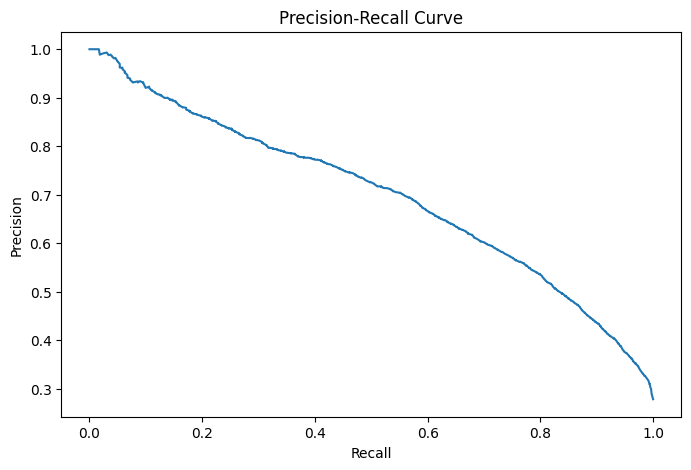

In [ ]:

from sklearn.metrics import precision_recall_curve

y_prob = rf_balanced.predict_proba(X_test)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(8, 5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.show()

##Choosing a threshold

In [ ]:
threshold =

y_pred_threshold = (
    y_prob >= threshold
).astype(int)

SyntaxError: invalid syntax (2828260339.py, line 1)

In [ ]:
print("Precision:", precision_score(y_test, y_pred_threshold))
print("Recall:", recall_score(y_test, y_pred_threshold))
print("F1:", f1_score(y_test, y_pred_threshold))

# Part 6 - The Tie-in

In [ ]:
# Cancellation rate within each cluster

cluster_cancellation = (
    df.groupby("cluster")["is_canceled"]
      .mean()
      .sort_values(ascending=False)
)

cluster_cancellation

### Cancellation Rate by Cluster

The cancellation rate is calculated within each K-Means cluster to determine whether the naturally occurring booking groups identified in the clustering analysis have different outcome patterns. A substantial difference in cancellation rates would indicate that some combinations of booking characteristics are associated with higher or lower cancellation rates.

### Interpretation

Cluster  had the highest observed cancellation rate at % while Cluster  had the lowest at  %. This suggests that the characteristics defining these clusters are associated with different cancellation patterns. However, clustering alone does not establish that the cluster characteristics cause cancellation; it identifies groups with different observed outcome rates.

# Part 7 - Conclusion and Recomendation

# Depth Track

## Clustering

## Classification

## Imbalance